# Turtle Breakout 12 — the risk portfolio at a survivable base risk (TB 11 repaired)

Pre-registration: `discussions/Turtle_Breakout/014_claude_tb12_preregistration.md`. Code: `turtle_portfolio.py` 0.2.0.

TB 11 put 2% of the high-water mark on every trade across 30 coins in one account and most runs were ruined, so its tests compared ruin with ruin. TB 12 changes two things only:
- **sizing on current equity** (risk, caps and open risk measured on the last marked equity);
- **base risk per trade** $f \in \{0.25\%, 0.5\%, 1\%\}$, **primary 0.5%** ($\approx 2\%/\sqrt{16}$); $H$ and $C$ grids scale with $f$ ($H \in \{2,3,4,5,7.5,10,15\}\,f$, $C \in \{1,2,3,4\}\,f$, the same position counts as TB 11).
Rules, windows and test are TB 11's: discovery 2020–2023 picks $H$, $C$ (Calmar); evaluation 2024 → end: Calmar(rule) − Calmar(R0m), Holm over 6 per $f$. **The evaluation window was already seen in TB 11.**

Environment: `TB01_DATA_DIR` (default `BINANCE_UM_DIR\long`), `TB12_SYNTHETIC=1`.

In [1]:
import os, sys, json, gc, time, subprocess, tempfile, warnings, platform
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 200)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_trade_features as tf, turtle_sizing as ts, turtle_reverse as tr, turtle_portfolio as tp

SYNTHETIC = os.getenv('TB12_SYNTHETIC', '0') == '1'
P = tb.Params(); RP = tr.RParams()
PP0 = replace(tp.PParams(), size_base='equity', status='PREREGISTERED_TB014')
FS = (0.0025, 0.005, 0.01); F_PRIMARY = 0.005
H_MULT = (2, 3, 4, 5, 7.5, 10, 15); C_MULT = (1, 2, 3, 4)
DISC0, DISC1 = tp.DISC; EVAL0 = tp.EVAL_START
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb12-')) / '12'; PP0 = replace(PP0, n_boot=300); H_MULT = (2, 5, 10); C_MULT = (1, 3)
    DISC0, DISC1, EVAL0 = pd.Timestamp('2021-07-01', tz='UTC'), pd.Timestamp('2023-07-01', tz='UTC'), pd.Timestamp('2023-07-01', tz='UTC')
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '12'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_portfolio.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
REG = {**tp.registration(PP0), 'f_values': FS, 'f_primary': F_PRIMARY, 'H_multiples_of_f': H_MULT, 'C_multiples_of_f': C_MULT,
       'size_base': 'equity', 'note': 'evaluation window already seen in TB 11'}
print(json.dumps(REG, indent=1, default=str))

OK
{
 "f": 0.02,
 "stop_atr": 2.0,
 "pos_cap": 3.0,
 "size_base": "equity",
 "start_equity": 100000.0,
 "H_grid": [
  0.04,
  0.06,
  0.08,
  0.1,
  0.15,
  0.2,
  0.3
 ],
 "C_grid": [
  0.02,
  0.04,
  0.06,
  0.08
 ],
 "K": 4,
 "min_take": 0.25,
 "corr_win": 60,
 "corr_min": 30,
 "corr_fallback": 0.7,
 "clus_win": 90,
 "clus_min": 60,
 "r4_min_trades": 10,
 "r4_max": 3.0,
 "block_days": 21,
 "n_boot": 2000,
 "alpha": 0.05,
 "seed": 20261101,
 "status": "PREREGISTERED_TB014",
 "version": "TB11-0.2.0",
 "rules": [
  "R0",
  "R1",
  "R2",
  "R3",
  "R4"
 ],
 "discovery": [
  "2020-01-01 00:00:00+00:00",
  "2024-01-01 00:00:00+00:00"
 ],
 "evaluation_start": "2024-01-01 00:00:00+00:00",
 "selection": "H (R1) and C (R3) maximise Calmar on DISCOVERY, per variant; ties -> smaller value",
 "decision": "EVALUATION: Calmar(rule) - Calmar(R0m) for R1, R2, R3 x {long, long_rev}; R0m = R0 with f scaled to the rule's mean open risk in the window (same exposure, no rule); paired 21-day block bootst

## 1. Books (as TB 11)

In [2]:
BOOKS = {'long': {}, 'long_rev': {}}; COV = []
if SYNTHETIC:
    BOOKS['long'] = tp.synthetic_books(10, 1100, seed=3, with_reverse=False)
    BOOKS['long_rev'] = tp.synthetic_books(10, 1100, seed=3, with_reverse=True)
    COV = pd.DataFrame([{'asset': a, 'longs': len(b.trades), 'reverses': int((BOOKS['long_rev'][a].trades.kind == 'reverse').sum())} for a, b in BOOKS['long'].items()])
else:
    for a in tf.UNIVERSE:
        t1 = time.time()
        pu = DATA / f'{a}USDT_um_1m.parquet'
        if not pu.exists():
            print(a, 'missing'); continue
        b, _ = tf.load_um(pu)
        fpth = DATA / 'basis' / 'funding' / f'{a}USDT_funding.parquet'
        f = tb.funding_events(pd.read_parquet(fpth)) if fpth.exists() else None
        if a == 'TON':
            b = b[b.index < tr.TON_CUTOFF]
        D = tb.prepare_asset(a, b, f, P)
        start = b.index[0] + pd.Timedelta(days=30)
        L0 = ts.trade_list(D, P, start, RP, with_reverse=False); L1 = ts.trade_list(D, P, start, RP, with_reverse=True)
        BOOKS['long'][a] = tp.make_book(D, L0, P); BOOKS['long_rev'][a] = tp.make_book(D, L1, P)
        COV.append({'asset': a, 'start': start, 'end': b.index[-1], 'longs': len(L0), 'reverses': int((L1.kind == 'reverse').sum())})
        print(f'{a}: {len(L0)} longs, {COV[-1]["reverses"]} reverses, {time.time() - t1:.0f}s')
        del b, D; gc.collect()
    COV = pd.DataFrame(COV)
display(COV)
RET = tp.returns_panel(BOOKS['long'])

BTC: 54 longs, 33 reverses, 2s
ETH: 50 longs, 25 reverses, 2s
SOL: 46 longs, 26 reverses, 1s
XRP: 47 longs, 30 reverses, 2s
BNB: 55 longs, 32 reverses, 2s
DOGE: 44 longs, 25 reverses, 1s
ADA: 51 longs, 37 reverses, 2s
LINK: 58 longs, 39 reverses, 2s
DOT: 45 longs, 32 reverses, 1s
LTC: 54 longs, 40 reverses, 2s
BCH: 52 longs, 36 reverses, 2s
UNI: 46 longs, 31 reverses, 1s
NEAR: 44 longs, 27 reverses, 1s
APT: 32 longs, 25 reverses, 1s
ARB: 26 longs, 17 reverses, 1s
OP: 34 longs, 24 reverses, 1s
SUI: 28 longs, 17 reverses, 1s
FIL: 41 longs, 28 reverses, 1s
ATOM: 52 longs, 36 reverses, 2s
ETC: 50 longs, 37 reverses, 2s
INJ: 35 longs, 22 reverses, 1s
AAVE: 52 longs, 37 reverses, 1s
TON: 38 longs, 34 reverses, 1s
WIF: 19 longs, 11 reverses, 1s
HBAR: 33 longs, 25 reverses, 1s
XLM: 53 longs, 36 reverses, 2s
SEI: 22 longs, 13 reverses, 1s
TIA: 25 longs, 18 reverses, 1s
ENA: 20 longs, 13 reverses, 1s
WLD: 26 longs, 17 reverses, 1s


,asset,start,end,longs,reverses
0,BTC,2020-01-31 00:05:00+00:00,2026-10-24 00:00:00+00:00,54,33
1,ETH,2020-01-31 00:05:00+00:00,2026-10-24 00:00:00+00:00,50,25
2,SOL,2020-10-14 07:05:00+00:00,2026-10-24 00:00:00+00:00,46,26
3,XRP,2020-02-05 08:25:00+00:00,2026-10-24 00:00:00+00:00,47,30
4,BNB,2020-03-11 08:05:00+00:00,2026-10-24 00:00:00+00:00,55,32
5,DOGE,2020-08-09 09:05:00+00:00,2026-10-24 00:00:00+00:00,44,25
6,ADA,2020-03-01 08:05:00+00:00,2026-10-24 00:00:00+00:00,51,37
7,LINK,2020-02-16 08:05:00+00:00,2026-10-24 00:00:00+00:00,58,39
8,DOT,2020-09-21 07:05:00+00:00,2026-10-24 00:00:00+00:00,45,32
9,LTC,2020-02-08 08:10:00+00:00,2026-10-24 00:00:00+00:00,54,40


## 2. Discovery, evaluation and tests for each f

In [3]:
def run(variant, rule, t0, t1, pp, books=None, **kw):
    o = tp.simulate(books or BOOKS[variant], rule, pp, t0, t1, R=RET, **kw)
    Dd = tp.daily_curve(o['equity'], pp.start_equity)
    return {**tp.metrics(Dd, pp.start_equity), 'max_open_risk': o['max_open_risk'], 'mean_open_risk': o['mean_open_risk'],
            'max_gross_lev': o['max_gross_lev'], **o['stats']}, Dd, o

DISC_ALL, EVAL_ALL, TEST_ALL, SEL_ALL, CURVES, OUTS = [], [], [], {}, {}, {}
T0 = time.time()
for f_ in FS:
    pp = replace(PP0, f=f_)
    for v in ('long', 'long_rev'):
        rows = []
        for rule, kw in [('R0', {}), ('R2', {}), ('R4', {})] + [('R1', {'H': m * f_}) for m in H_MULT] + [('R3', {'C': m * f_}) for m in C_MULT]:
            m, _, _ = run(v, rule, DISC0, DISC1, pp, **kw)
            rows.append({'f': f_, 'variant': v, 'rule': rule, 'H': kw.get('H', np.nan), 'C': kw.get('C', np.nan), **m})
        g = pd.DataFrame(rows); DISC_ALL.append(g)
        sel = {'H': tp.select(g[g.rule == 'R1'], 'H'), 'C': tp.select(g[g.rule == 'R3'], 'C')}; SEL_ALL[(f_, v)] = sel
        for rule, kw in (('R0', {}), ('R1', {'H': sel['H']}), ('R2', {}), ('R3', {'C': sel['C']}), ('R4', {})):
            m, Dd, o = run(v, rule, EVAL0, None, pp, **kw)
            EVAL_ALL.append({'f': f_, 'variant': v, 'rule': rule, 'param': kw.get('H', kw.get('C', np.nan)), **m}); CURVES[(f_, v, rule)] = Dd; OUTS[(f_, v, rule)] = o
        r0 = OUTS[(f_, v, 'R0')]['mean_open_risk']
        for rule in ('R1', 'R2', 'R3'):
            fm = f_ * OUTS[(f_, v, rule)]['mean_open_risk'] / r0
            m, Dd, o = run(v, 'R0', EVAL0, None, replace(pp, f=fm))
            EVAL_ALL.append({'f': f_, 'variant': v, 'rule': f'R0m_for_{rule}', 'param': fm, **m}); CURVES[(f_, v, f'R0m_{rule}')] = Dd
            t = tp.calmar_diff(CURVES[(f_, v, rule)], Dd, pp, pp.seed + len(TEST_ALL))
            t0 = tp.calmar_diff(CURVES[(f_, v, rule)], CURVES[(f_, v, 'R0')], pp, pp.seed + 100 + len(TEST_ALL))
            TEST_ALL.append({'f': f_, 'variant': v, 'rule': rule, 'f_R0m': fm, **t, 'vs_R0_calmar_diff': t0['calmar_diff'], 'vs_R0_lo95': t0['lo95'], 'vs_R0_hi95': t0['hi95'], 'vs_R0_p': t0['p']})
    print(f'f = {f_:.2%} done, {time.time() - T0:.0f}s')
DISC = pd.concat(DISC_ALL, ignore_index=True); EVAL = pd.DataFrame(EVAL_ALL); TESTS = pd.DataFrame(TEST_ALL)
TESTS['p_holm'] = np.nan
for f_ in FS:
    m = TESTS.f == f_; TESTS.loc[m, 'p_holm'] = tp.holm(TESTS.loc[m, 'p'].to_numpy())
TESTS['result'] = np.where(TESTS.p_holm < PP0.alpha, 'IMPROVES', 'NO_DIFFERENCE')
print('selected H, C:', {f'{k[0]:.2%} {k[1]}': v for k, v in SEL_ALL.items()})
cols = ['f', 'variant', 'rule', 'cagr', 'max_dd', 'calmar', 'sharpe', 'ruined', 'max_open_risk', 'mean_open_risk', 'max_gross_lev', 'entries', 'skipped', 'scaled']
print('Discovery'); display(DISC[cols[:2] + ['rule', 'H', 'C'] + cols[3:]].round(3))
print('Evaluation'); display(EVAL[cols[:3] + ['param'] + cols[3:]].round(3))
display(TESTS.round(4))

f = 0.25% done, 154s
f = 0.50% done, 307s
f = 1.00% done, 460s
selected H, C: {'0.25% long': {'H': 0.01, 'C': 0.01}, '0.25% long_rev': {'H': 0.0375, 'C': 0.005}, '0.50% long': {'H': 0.02, 'C': 0.02}, '0.50% long_rev': {'H': 0.075, 'C': 0.01}, '1.00% long': {'H': 0.04, 'C': 0.04}, '1.00% long_rev': {'H': 0.15, 'C': 0.02}}
Discovery


,f,variant,rule,H,C,cagr,max_dd,calmar,sharpe,ruined,max_open_risk,mean_open_risk,max_gross_lev,entries,skipped,scaled
0,0.002,long,R0,NaN,NaN,0.285,-0.202,1.408,1.299,False,0.059,0.016,0.887,580,0,0
1,0.002,long,R2,NaN,NaN,0.091,-0.093,0.973,1.384,False,0.013,0.004,0.248,580,0,552
2,0.002,long,R4,NaN,NaN,0.293,-0.201,1.455,1.288,False,0.070,0.016,0.900,547,33,0
3,0.002,long,R1,0.005,NaN,0.053,-0.068,0.782,1.054,False,0.005,0.003,0.194,103,477,15
4,0.002,long,R1,0.008,NaN,0.084,-0.051,1.639,1.271,False,0.008,0.004,0.230,151,429,23
5,0.002,long,R1,0.010,NaN,0.119,-0.057,2.089,1.509,False,0.010,0.006,0.258,189,391,25
6,0.002,long,R1,0.012,NaN,0.134,-0.075,1.770,1.473,False,0.013,0.007,0.272,231,349,24
7,0.002,long,R1,0.019,NaN,0.186,-0.169,1.100,1.375,False,0.019,0.009,0.358,340,240,57
8,0.002,long,R1,0.025,NaN,0.216,-0.182,1.188,1.363,False,0.026,0.011,0.472,412,168,32
9,0.002,long,R1,0.038,NaN,0.262,-0.188,1.392,1.318,False,0.038,0.014,0.660,518,62,23


Evaluation


,f,variant,rule,param,cagr,max_dd,calmar,sharpe,ruined,max_open_risk,mean_open_risk,max_gross_lev,entries,skipped,scaled
0,0.002,long,R0,NaN,0.169,-0.253,0.669,0.762,False,0.072,0.020,0.980,652,0,0
1,0.002,long,R1,0.010,0.006,-0.112,0.051,0.126,False,0.010,0.006,0.177,191,461,20
2,0.002,long,R2,NaN,0.021,-0.069,0.307,0.488,False,0.017,0.004,0.194,652,0,629
3,0.002,long,R3,0.010,0.021,-0.139,0.152,0.272,False,0.023,0.008,0.342,284,368,15
4,0.002,long,R4,NaN,0.139,-0.233,0.598,0.696,False,0.070,0.020,1.027,584,68,0
5,0.002,long,R0m_for_R1,0.001,0.058,-0.090,0.637,0.738,False,0.021,0.006,0.348,652,0,0
6,0.002,long,R0m_for_R2,0.001,0.045,-0.071,0.631,0.734,False,0.016,0.005,0.278,652,0,0
7,0.002,long,R0m_for_R3,0.001,0.077,-0.119,0.646,0.744,False,0.029,0.008,0.449,652,0,0
8,0.002,long_rev,R0,NaN,0.207,-0.221,0.938,0.874,False,0.077,0.037,0.993,1104,0,0
9,0.002,long_rev,R1,0.038,0.147,-0.158,0.935,0.894,False,0.039,0.028,0.668,852,252,107


,f,variant,rule,f_R0m,calmar_diff,lo95,hi95,p,vs_R0_calmar_diff,vs_R0_lo95,vs_R0_hi95,vs_R0_p,p_holm,result
0,0.0025,long,R1,0.0007,-0.5857,-2.4755,0.3233,0.8431,-0.6171,-2.8949,0.4157,0.8176,1.0,NO_DIFFERENCE
1,0.0025,long,R2,0.0006,-0.3234,-1.2760,0.2011,0.8501,-0.3614,-2.0585,0.1410,0.8276,1.0,NO_DIFFERENCE
2,0.0025,long,R3,0.0010,-0.4942,-1.7294,0.0616,0.9510,-0.5168,-2.1258,0.0669,0.9340,1.0,NO_DIFFERENCE
3,0.0025,long_rev,R1,0.0019,0.0189,-0.6245,0.6772,0.4468,-0.0031,-0.8067,0.5143,0.4788,1.0,NO_DIFFERENCE
4,0.0025,long_rev,R2,0.0006,-0.4363,-1.6462,0.2439,0.8656,-0.5309,-2.4190,0.2003,0.8671,1.0,NO_DIFFERENCE
5,0.0025,long_rev,R3,0.0006,0.2529,-1.2313,1.6924,0.5017,0.1595,-1.6226,1.5517,0.5427,1.0,NO_DIFFERENCE
6,0.0050,long,R1,0.0015,-0.6247,-3.0019,0.3760,0.8401,-0.6098,-3.7666,0.3693,0.7886,1.0,NO_DIFFERENCE
7,0.0050,long,R2,0.0011,-0.3482,-1.3595,0.1914,0.8531,-0.3412,-2.6853,0.1695,0.7626,1.0,NO_DIFFERENCE
8,0.0050,long,R3,0.0020,-0.5381,-1.9047,0.0397,0.9615,-0.5155,-2.4884,0.0859,0.9015,1.0,NO_DIFFERENCE
9,0.0050,long_rev,R1,0.0038,-0.0668,-0.8283,0.6240,0.5292,-0.0640,-1.0807,0.5087,0.5342,1.0,NO_DIFFERENCE


## 3. Decision (f = 0.5%)

In [4]:
TP = TESTS[TESTS.f == F_PRIMARY]
DEC = {'f': F_PRIMARY, 'selected': {v: SEL_ALL[(F_PRIMARY, v)] for v in ('long', 'long_rev')},
       'tests': TP[['variant', 'rule', 'calmar_diff', 'lo95', 'hi95', 'p', 'p_holm', 'result']].to_dict('records'),
       'any_ruined_in_evaluation': bool(EVAL[(EVAL.f == F_PRIMARY)].ruined.any())}
imp = [f'{r.rule}/{r.variant}' for r in TP.itertuples() if r.result == 'IMPROVES']
DEC['verdict'] = 'RULE_IMPROVES: ' + ', '.join(imp) if imp else 'NO_RULE_BEATS_SAME_EXPOSURE'
print(json.dumps(DEC, indent=1, default=float))

{
 "f": 0.005,
 "selected": {
  "long": {
   "H": 0.02,
   "C": 0.02
  },
  "long_rev": {
   "H": 0.075,
   "C": 0.01
  }
 },
 "tests": [
  {
   "variant": "long",
   "rule": "R1",
   "calmar_diff": -0.6247237720397895,
   "lo95": -3.0018852101627265,
   "hi95": 0.3759872541996565,
   "p": 0.84007996001999,
   "p_holm": 1.0,
   "result": "NO_DIFFERENCE"
  },
  {
   "variant": "long",
   "rule": "R2",
   "calmar_diff": -0.34818729161666534,
   "lo95": -1.3595365386286482,
   "hi95": 0.1914198608232391,
   "p": 0.8530734632683659,
   "p_holm": 1.0,
   "result": "NO_DIFFERENCE"
  },
  {
   "variant": "long",
   "rule": "R3",
   "calmar_diff": -0.5380763429307454,
   "lo95": -1.9046926405554947,
   "hi95": 0.03968753144651601,
   "p": 0.9615192403798101,
   "p_holm": 1.0,
   "result": "NO_DIFFERENCE"
  },
  {
   "variant": "long_rev",
   "rule": "R1",
   "calmar_diff": -0.06679819105668972,
   "lo95": -0.8283058907578746,
   "hi95": 0.6239769400860734,
   "p": 0.5292353823088456,
   "p_hol

## 4. Reported: reverse vs long, sleeves, full period, 4-coin portfolio (f = 0.5%)

In [5]:
pp = replace(PP0, f=F_PRIMARY)
rows = []
for f_ in FS:
    for rule in ('R0', 'R1', 'R2', 'R3', 'R4'):
        t = tp.calmar_diff(CURVES[(f_, 'long_rev', rule)], CURVES[(f_, 'long', rule)], pp, pp.seed + 500)
        e = EVAL.set_index(['f', 'variant', 'rule'])
        rows.append({'f': f_, 'rule': rule, 'calmar_long': e.loc[(f_, 'long', rule), 'calmar'], 'calmar_long_rev': e.loc[(f_, 'long_rev', rule), 'calmar'],
                     'dd_long': e.loc[(f_, 'long', rule), 'max_dd'], 'dd_long_rev': e.loc[(f_, 'long_rev', rule), 'max_dd'], **t})
REV = pd.DataFrame(rows); print('Evaluation: long + reverse minus long (Calmar)'); display(REV.round(3))

SLV = []
pps = tp.PParams()            # TB 10 sleeves: each coin its own account, 2% of its HWM
for v in ('long', 'long_rev'):
    for name, (a0, a1) in (('discovery', (DISC0, DISC1)), ('evaluation', (EVAL0, None))):
        cur = {}
        for a, bk in BOOKS[v].items():
            o = tp.simulate({a: bk}, 'R0', pps, a0, a1)
            if len(o['equity']) > 30 and o['stats']['entries'] > 0:
                cur[a] = tp.daily_curve(o['equity'], pps.start_equity)
        lr = ts.pooled_log_returns(cur); Dd = pps.start_equity * np.exp(lr.cumsum())
        SLV.append({'variant': v, 'window': name, 'coins': len(cur), **tp.metrics(Dd, pps.start_equity)})
        if name == 'evaluation':
            CURVES[(F_PRIMARY, v, 'sleeves')] = Dd
SLV = pd.DataFrame(SLV); print('Equal-weight sleeves'); display(SLV.round(3))

FULL = []
for v in ('long', 'long_rev'):
    sel = SEL_ALL[(F_PRIMARY, v)]
    for rule, kw in (('R0', {}), ('R1', {'H': sel['H']}), ('R2', {}), ('R3', {'C': sel['C']}), ('R4', {})):
        m, _, _ = run(v, rule, DISC0, None, pp, **kw); FULL.append({'variant': v, 'rule': rule, **m})
        if not SYNTHETIC:
            core = {a: BOOKS[v][a] for a in tf.CONFIRM_ASSETS if a in BOOKS[v]}
            m4, _, _ = run(v, rule, tb.COMMON_START, None, pp, books=core, **kw); FULL.append({'variant': v, 'rule': rule + '_4coins', **m4})
FULL = pd.DataFrame(FULL); print('Full period and 4-coin portfolio, f = 0.5%')
display(FULL[cols[1:]].round(3))

Evaluation: long + reverse minus long (Calmar)


,f,rule,calmar_long,calmar_long_rev,dd_long,dd_long_rev,calmar_diff,lo95,hi95,p
0,0.002,R0,0.669,0.938,-0.253,-0.221,0.270,-0.790,1.485,0.333
1,0.002,R1,0.051,0.935,-0.112,-0.158,0.884,-0.391,3.424,0.132
2,0.002,R2,0.307,0.407,-0.069,-0.051,0.100,-0.938,0.984,0.468
3,0.002,R3,0.152,1.098,-0.139,-0.064,0.946,-0.184,2.756,0.100
4,0.002,R4,0.598,0.751,-0.233,-0.215,0.153,-0.845,1.281,0.377
5,0.005,R0,0.643,0.955,-0.419,-0.365,0.312,-0.984,1.891,0.334
6,0.005,R1,0.033,0.891,-0.212,-0.290,0.858,-0.391,3.791,0.142
7,0.005,R2,0.302,0.398,-0.131,-0.097,0.096,-0.987,1.011,0.474
8,0.005,R3,0.128,0.973,-0.260,-0.123,0.845,-0.231,2.834,0.112
9,0.005,R4,0.541,0.718,-0.405,-0.370,0.177,-1.041,1.590,0.378


Equal-weight sleeves


,variant,window,coins,cagr,log_growth,max_dd,calmar,sharpe,ruined,final_multiple
0,long,discovery,27,0.081,0.078,-0.075,1.078,1.155,False,1.365
1,long,evaluation,30,0.045,0.044,-0.093,0.478,0.612,False,1.130
2,long_rev,discovery,27,0.084,0.080,-0.050,1.661,1.170,False,1.380
3,long_rev,evaluation,30,0.053,0.051,-0.081,0.651,0.702,False,1.156


Full period and 4-coin portfolio, f = 0.5%


,variant,rule,cagr,max_dd,calmar,sharpe,ruined,max_open_risk,mean_open_risk,max_gross_lev,entries,skipped,scaled
0,long,R0,0.412,-0.419,0.982,1.048,False,0.144,0.034,1.808,1232,0,0
1,long,R0_4coins,0.154,-0.093,1.652,1.422,False,0.020,0.007,0.457,178,0,0
2,long,R1,0.137,-0.212,0.645,1.008,False,0.021,0.011,0.471,390,842,64
3,long,R1_4coins,0.154,-0.093,1.652,1.422,False,0.020,0.007,0.457,178,0,4
4,long,R2,0.118,-0.168,0.703,1.071,False,0.034,0.009,0.468,1232,0,1183
5,long,R2_4coins,0.085,-0.052,1.652,1.382,False,0.013,0.004,0.320,178,0,131
6,long,R3,0.242,-0.260,0.931,1.106,False,0.050,0.016,0.655,589,643,60
7,long,R3_4coins,0.154,-0.093,1.652,1.422,False,0.020,0.007,0.457,178,0,4
8,long,R4,0.392,-0.405,0.970,1.022,False,0.141,0.034,1.872,1131,101,0
9,long,R4_4coins,0.143,-0.096,1.492,1.382,False,0.021,0.007,0.454,178,0,0


## 5. Figures (f = 0.5%)

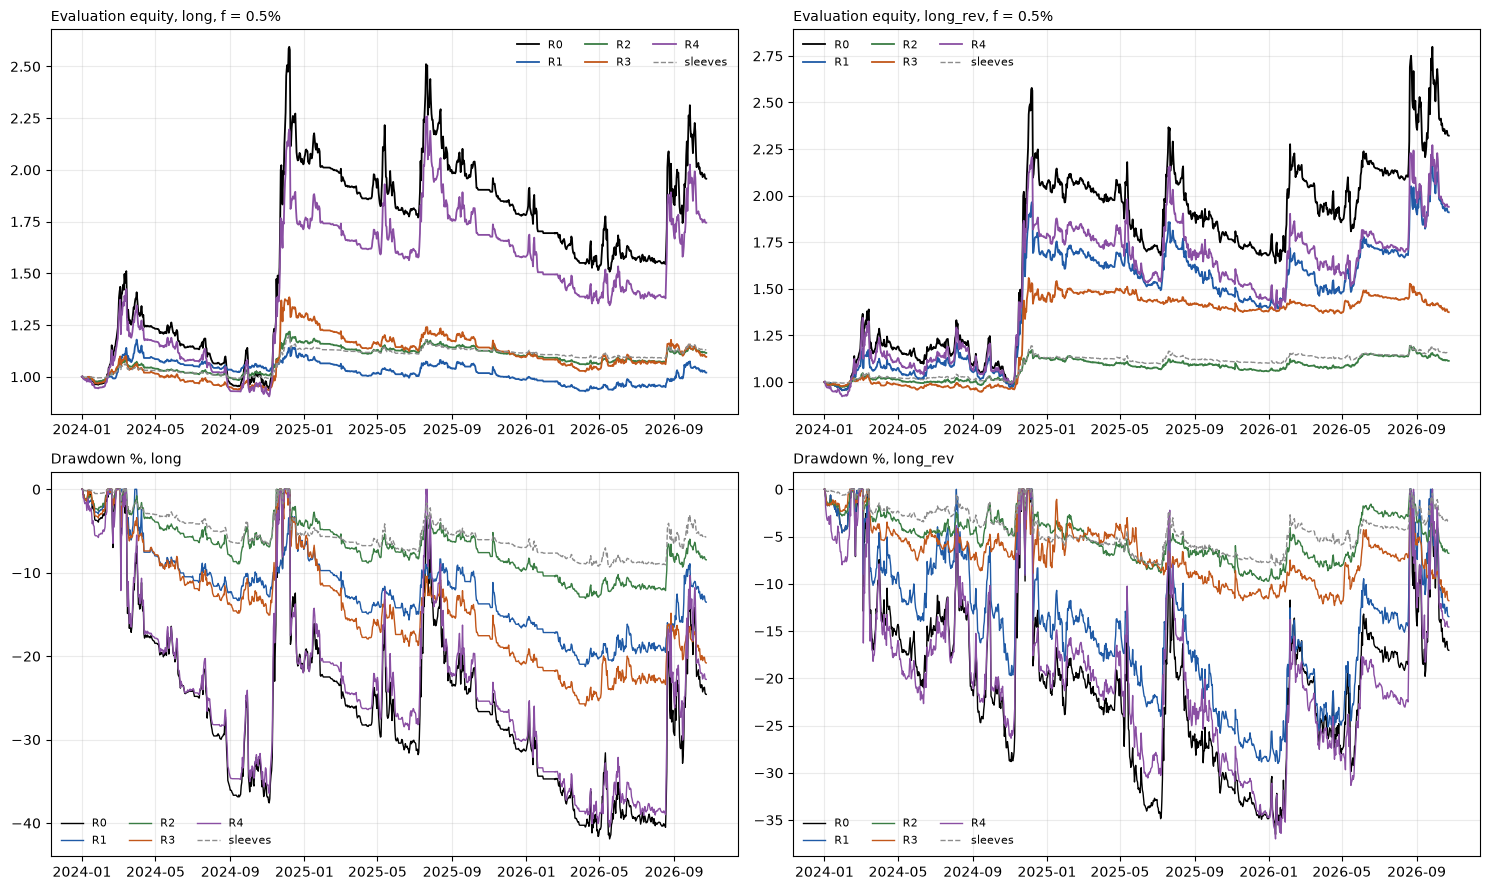

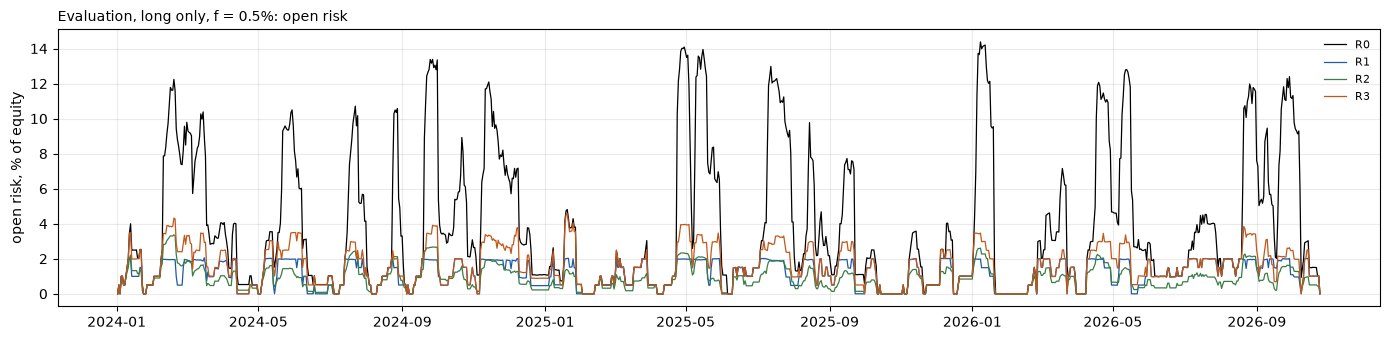

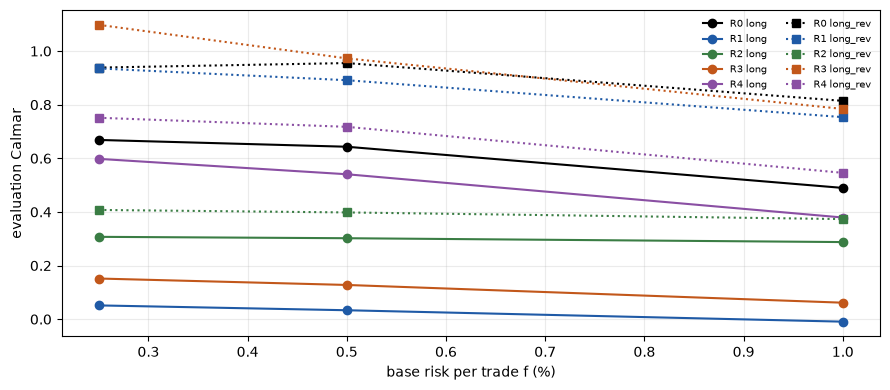

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
colors = {'R0': 'k', 'R1': '#1f5aa6', 'R2': '#3a7d44', 'R3': '#c2571a', 'R4': '#8a4fa3', 'sleeves': '0.55'}
for j, v in enumerate(('long', 'long_rev')):
    for rule in ('R0', 'R1', 'R2', 'R3', 'R4', 'sleeves'):
        c = CURVES[(F_PRIMARY, v, rule)]
        axes[0, j].plot(c.index, c / c.iloc[0], color=colors[rule], lw=1.3 if rule != 'sleeves' else 1.0, ls='-' if rule != 'sleeves' else '--', label=rule)
        axes[1, j].plot(c.index, (c / c.cummax() - 1) * 100, color=colors[rule], lw=1.0, ls='-' if rule != 'sleeves' else '--', label=rule)
    axes[0, j].set_title(f'Evaluation equity, {v}, f = 0.5%', loc='left', fontsize=10); axes[1, j].set_title(f'Drawdown %, {v}', loc='left', fontsize=10)
    for a in axes[:, j]:
        a.grid(alpha=0.25); a.legend(frameon=False, fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 3.5))
for rule in ('R0', 'R1', 'R2', 'R3'):
    s = OUTS[(F_PRIMARY, 'long', rule)]['open_risk']; ax.plot(s.index, s * 100, color=colors[rule], lw=0.9, label=rule)
ax.set_ylabel('open risk, % of equity'); ax.set_title('Evaluation, long only, f = 0.5%: open risk', loc='left', fontsize=10); ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for (v, mk) in (('long', 'o'), ('long_rev', 's')):
    for rule in ('R0', 'R1', 'R2', 'R3', 'R4'):
        e = EVAL[(EVAL.variant == v) & (EVAL.rule == rule)]
        ax.plot(e.f * 100, e.calmar, marker=mk, color=colors[rule], ls='-' if v == 'long' else ':', label=f'{rule} {v}')
ax.set_xlabel('base risk per trade f (%)'); ax.set_ylabel('evaluation Calmar'); ax.legend(frameon=False, fontsize=7, ncol=2); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 6. Save

In [7]:
DISC.to_csv(OUT / '12_discovery.csv', index=False); EVAL.to_csv(OUT / '12_evaluation.csv', index=False); TESTS.to_csv(OUT / '12_tests.csv', index=False)
REV.to_csv(OUT / '12_reverse_vs_long.csv', index=False); SLV.to_csv(OUT / '12_sleeves.csv', index=False); FULL.to_csv(OUT / '12_full_and_4coins.csv', index=False)
COV.to_csv(OUT / '12_coverage.csv', index=False)
pd.DataFrame({f'{k[0]}|{k[1]}|{k[2]}': c for k, c in CURVES.items()}).to_csv(OUT / '12_eval_curves.csv.gz', compression='gzip')
(OUT / '12_decision.json').write_text(json.dumps({'decision': DEC, 'registration': REG, 'synthetic': SYNTHETIC}, indent=1, default=str))
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '12_manifest.json').write_text(json.dumps({'version': tp.VERSION, 'git': git, 'python': platform.python_version(),
    'created_utc': pd.Timestamp.now('UTC').isoformat(), 'coins': list(BOOKS['long']), 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print('VERDICT:', DEC['verdict'])

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\12
VERDICT: NO_RULE_BEATS_SAME_EXPOSURE
